In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns



In [3]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [4]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score , root_mean_squared_error 


In [6]:
df = pd.read_csv("housing.csv")

In [7]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [8]:
df.shape

(20640, 10)

EDA

In [9]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [11]:
num_col=df.select_dtypes(include=np.number).columns.tolist()
cat_col=df.select_dtypes(exclude=np.number).columns.tolist()


In [12]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [13]:
for col in df.columns:
    print(df[col].value_counts())

longitude
-118.31    162
-118.30    160
-118.29    148
-118.27    144
-118.32    142
          ... 
-123.25      1
-123.28      1
-123.13      1
-123.12      1
-123.43      1
Name: count, Length: 844, dtype: int64
latitude
34.06    244
34.05    236
34.08    234
34.07    231
34.04    221
        ... 
35.97      1
35.86      1
35.85      1
35.89      1
35.88      1
Name: count, Length: 862, dtype: int64
housing_median_age
52.0    1273
36.0     862
35.0     824
16.0     771
17.0     698
34.0     689
26.0     619
33.0     615
18.0     570
25.0     566
32.0     565
37.0     537
15.0     512
19.0     502
27.0     488
24.0     478
30.0     476
28.0     471
20.0     465
29.0     461
31.0     458
23.0     448
21.0     446
14.0     412
22.0     399
38.0     394
39.0     369
42.0     368
44.0     356
43.0     353
40.0     304
13.0     302
41.0     296
45.0     294
10.0     264
11.0     254
46.0     245
5.0      244
12.0     238
8.0      206
9.0      205
47.0     198
4.0      191
48.0     177
7.0 

In [14]:
duplicate_mask = df.duplicated()
num_duplicates=duplicate_mask.sum()
num_duplicates



np.int64(0)

In [15]:
df[num_col].describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


data visualization

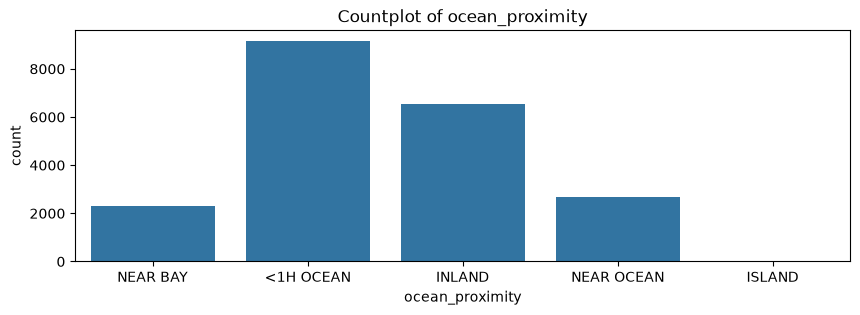

In [16]:
for col in cat_col:
    plt.figure(figsize=(10,3))
    sns.countplot(x=col, data=df)
    plt.title(f"Countplot of {col}")
    plt.show()

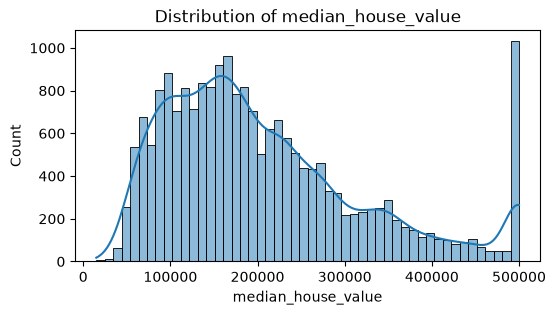

In [17]:
#target column distribution
plt.figure(figsize=(6,3))
sns.histplot(df["median_house_value"],bins=50, kde=True)
plt.title(f"Distribution of {df['median_house_value'].name}")
plt.show()

In [18]:
df["median_house_value"].value_counts()

median_house_value
500001.0    965
137500.0    122
162500.0    117
112500.0    103
187500.0     93
           ... 
422900.0      1
349400.0      1
425800.0      1
200700.0      1
47000.0       1
Name: count, Length: 3842, dtype: int64

histogram plot distribution

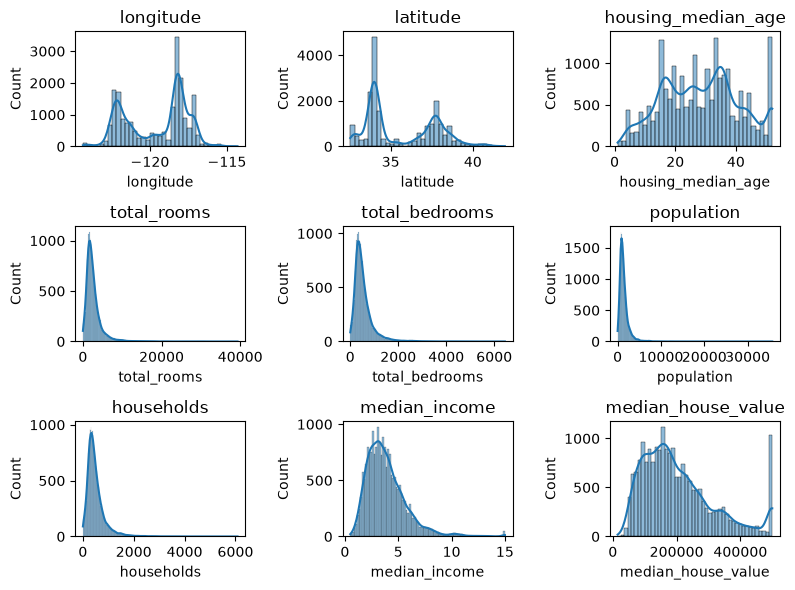

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(8, 6))
axes = axes.flatten()
for i, col in enumerate(num_col):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

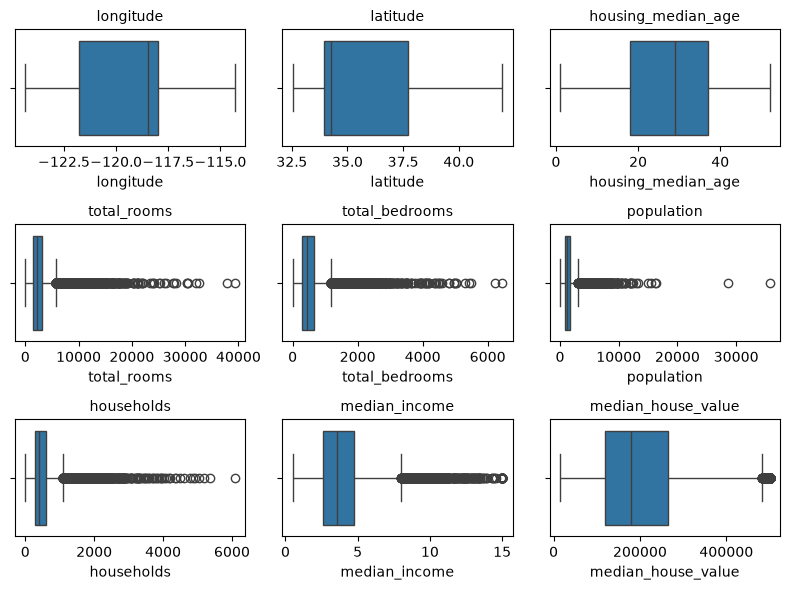

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(8, 6))
axes = axes.flatten()
for i, col in enumerate(num_col):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col,fontsize=10)
    axes[i].set_xlabel
plt.tight_layout()
plt.show()

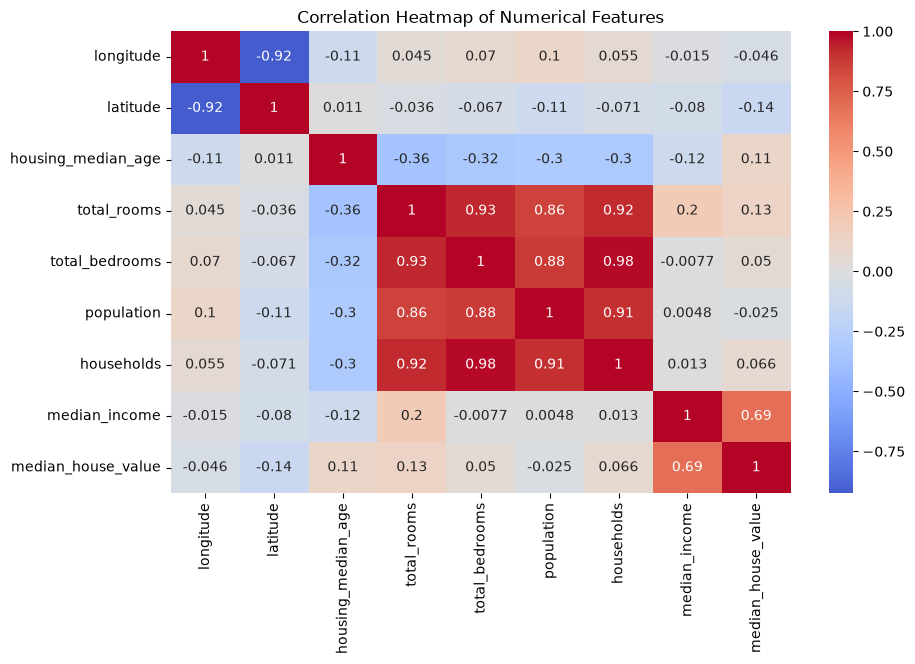

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_col].corr(), annot=True, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

correlation with target

In [22]:
corr_with_target = df[num_col].corr()["median_house_value"].sort_values(ascending=False)
print(corr_with_target)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


data preprocessing

what is data leakage ???????????

seprate feature and target

In [23]:
x=df.drop("median_house_value", axis=1)
y=df["median_house_value"]

In [24]:
x.head
y.head()

0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [26]:
x_test.shape

(4128, 9)

preprocessing pipeline

In [27]:
numerical_features = x_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = x_train.select_dtypes(exclude=[np.number]).columns.tolist()
# print(categorical_features)

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

processor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

baseline model(no cv no tuning)

In [28]:
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', processor),
    ('model', LinearRegression())
])

preprocesss the data and train the baseline model

In [29]:
baseline_pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [30]:
train_baseline_predictions = baseline_pipeline.predict(x_train)
test_baseline_predictions = baseline_pipeline.predict(x_test)

In [31]:
train_baseline_predictions[:5]

array([188628.07724361, 290379.8948687 , 250985.48476349, 146878.07878194,
       165789.41368924])

In [32]:
y_train[:5]

14196    103000.0
8267     382100.0
17445    172600.0
14265     93400.0
2271      96500.0
Name: median_house_value, dtype: float64

In [33]:
train_baseline_rmse = root_mean_squared_error(y_train, train_baseline_predictions)
train_baseline_mae = mean_absolute_error(y_test, test_baseline_predictions)
train_baseline_r2 = r2_score(y_train, train_baseline_predictions)


print(f"Train RMSE: {train_baseline_rmse:.2f}")
print(f"Train MAE: {train_baseline_mae:.2f}")
print(f"Train R2: {train_baseline_r2:.2f}")


Train RMSE: 68433.94
Train MAE: 50670.49
Train R2: 0.65


In [34]:
test_baseline_rmse = root_mean_squared_error(y_test, test_baseline_predictions)
test_baseline_mae = mean_absolute_error(y_test, test_baseline_predictions)
test_baseline_r2 = r2_score(y_test, test_baseline_predictions)


print(f"Test RMSE: {test_baseline_rmse:.2f}")
print(f"Test MAE: {test_baseline_mae:.2f}")
print(f"Test R2: {test_baseline_r2:.3f}")


Test RMSE: 70059.19
Test MAE: 50670.49
Test R2: 0.625


model selection and optimization

In [35]:
models = {
    'Linear Regression': LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Lasso Regression": Lasso(random_state=42, max_iter=10000),
    "RandomForestRegressor": RandomForestRegressor(random_state=42),
    "HistGradientBoostingRegressor": HistGradientBoostingRegressor()
}

In [36]:
k=5
cv = KFold(n_splits=k, shuffle=True, random_state=42)


In [37]:
scoring={
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

In [38]:
rows = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', processor),
        ('model', model)
    ])
    
    score = cross_validate(pipeline, x_train, y_train, cv=cv, scoring=scoring)

    rows.append({
        'Model': name,
        'cv_RMSE': -score['test_RMSE'].mean(),
        'cv_MAE': -score['test_MAE'].mean(),
        'cv_R2': score['test_R2'].mean()
    })

    cv_results=pd.DataFrame(rows).sort_values("cv_RMSE")
    print(cv_results)

               Model       cv_RMSE        cv_MAE     cv_R2
0  Linear Regression  68604.162955  49667.159067  0.647676
               Model       cv_RMSE        cv_MAE     cv_R2
1   Ridge Regression  68595.617399  49664.330927  0.647760
0  Linear Regression  68604.162955  49667.159067  0.647676
               Model       cv_RMSE        cv_MAE     cv_R2
1   Ridge Regression  68595.617399  49664.330927  0.647760
2   Lasso Regression  68603.233277  49667.262611  0.647685
0  Linear Regression  68604.162955  49667.159067  0.647676
                   Model       cv_RMSE        cv_MAE     cv_R2
3  RandomForestRegressor  49445.286035  32328.532731  0.817076
1       Ridge Regression  68595.617399  49664.330927  0.647760
2       Lasso Regression  68603.233277  49667.262611  0.647685
0      Linear Regression  68604.162955  49667.159067  0.647676
                           Model       cv_RMSE        cv_MAE     cv_R2
4  HistGradientBoostingRegressor  48336.433132  32422.780306  0.825171
3          R

In [39]:
score

{'fit_time': array([0.33048177, 0.4644835 , 0.67515445, 0.35981131, 0.45142651]),
 'score_time': array([0.01377797, 0.02792406, 0.01234674, 0.01506305, 0.01719356]),
 'test_RMSE': array([-49925.03097067, -48025.87889666, -47221.91540799, -49484.29767061,
        -47025.0427151 ]),
 'test_MAE': array([-33531.01766135, -32133.20735407, -31912.16773686, -32754.01498181,
        -31783.49379625]),
 'test_R2': array([0.81938184, 0.82636178, 0.83278872, 0.81823143, 0.8290927 ])}

In [40]:
cv_results 

,Model,cv_RMSE,cv_MAE,cv_R2
4,HistGradientBoostingRegressor,48336.433132,32422.780306,0.825171
3,RandomForestRegressor,49445.286035,32328.532731,0.817076
1,Ridge Regression,68595.617399,49664.330927,0.647760
2,Lasso Regression,68603.233277,49667.262611,0.647685
0,Linear Regression,68604.162955,49667.159067,0.647676


In [41]:
best_model=cv_results.sort_values("cv_RMSE").iloc[0]
best_model
best_model_name = best_model['Model']
best_RMSE = best_model['cv_RMSE']
print(best_model_name)

HistGradientBoostingRegressor


hyperparameter tuning 

In [42]:
HistGradientBoosting_pipeline = Pipeline(steps=[
    ('preprocessor', processor),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

hyperparameter combination


In [43]:
param_grid = {
    "model__max_depth": [None, 3, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 0.1, 1]
}

In [44]:
grid_search = GridSearchCV(
    estimator=HistGradientBoosting_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    refit=True,
    n_jobs=1,
    verbose=1
)

In [45]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__l2_regularization': [0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [None, 3, ...], 'model__max_leaf_nodes': [15, 31, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See 

In [46]:
-grid_search.best_score_
grid_search.best_score_


np.float64(-47327.96653299736)

retarining with best params


In [47]:
HistGradientBoostingRegressor_best=Pipeline(steps=[
    ('preprocessor', processor),
    ('model', HistGradientBoostingRegressor(l2_regularization=0.1, learning_rate=0.1, max_depth=None, max_leaf_nodes=63, min_samples_leaf=20))
])


In [48]:
grid_search.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [49]:
 HistGradientBoostingRegressor_best.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

final wvaluation 

In [50]:
train_final_predictions = HistGradientBoostingRegressor_best.predict(x_train)

train_final_RMSE = root_mean_squared_error(y_train, train_final_predictions)    
train_final_mae = mean_absolute_error(y_train, train_final_predictions)
train_final_r2 = r2_score(y_train, train_final_predictions)

print(f"Train RMSE: {train_final_RMSE:.2f}")
print(f"Train MAE: {train_final_mae:.2f}") 
print(f"Train R2: {train_final_r2:.3f}")

Train RMSE: 35846.47
Train MAE: 24446.46
Train R2: 0.904


In [51]:
test_final_predictions = HistGradientBoostingRegressor_best.predict(x_test) 
test_final_RMSE = root_mean_squared_error(y_test, test_final_predictions)
test_final_mae = mean_absolute_error(y_test, test_final_predictions)
test_final_r2 = r2_score(y_test, test_final_predictions)

print(f"Test RMSE: {test_final_RMSE:.2f}")
print(f"Test MAE: {test_final_mae:.2f}") 
print(f"Test R2: {test_final_r2:.3f}")

Test RMSE: 46550.55
Test MAE: 30755.81
Test R2: 0.835


residual plot

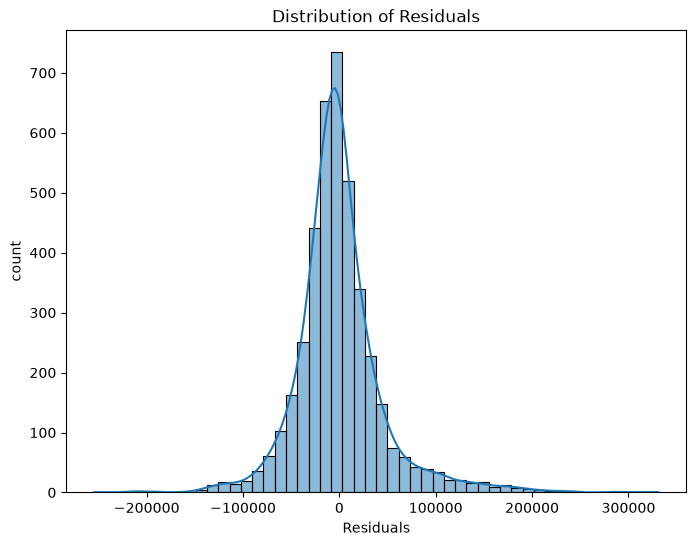

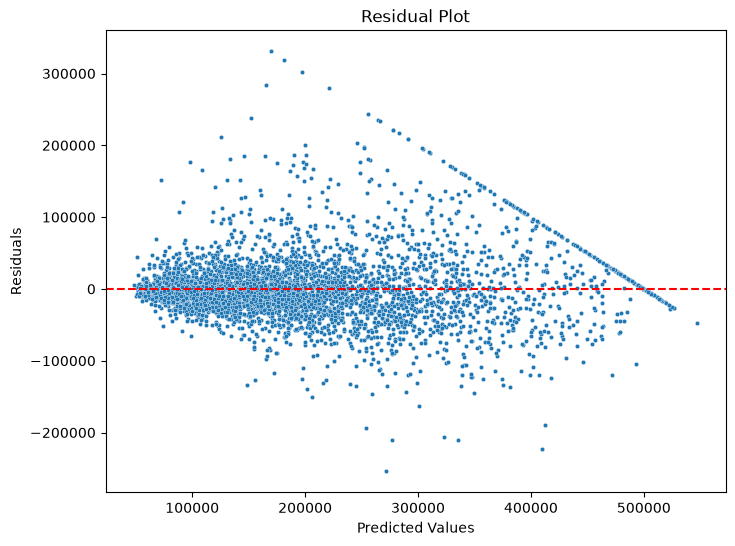

In [55]:
residual = y_test - test_final_predictions
plt.figure(figsize=(8, 6))
sns.histplot(residual, bins=50, kde=True)
plt.xlabel('Residuals')
plt.ylabel('count')
plt.title('Distribution of Residuals')
plt.show()
plt.figure(figsize=(8, 6))
sns.scatterplot(x=test_final_predictions, y=residual,s=10)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()


building a predictive system

In [62]:
def predict_house_value(
        model,
        longitude:float,
        latitude:float,
        housing_median_age:float,
        total_rooms:float,
        total_bedrooms:float,
        population:float,
        households:float,
        median_income:float,
        ocean_proximity:str
) -> float:
    new_row = pd.DataFrame({
        'longitude': [longitude],
        'latitude': [latitude],
        'housing_median_age': [housing_median_age],
        'total_rooms': [total_rooms],
        'total_bedrooms': [total_bedrooms],
        'population': [population],
        'households': [households],
        'median_income': [median_income],
        'ocean_proximity': [ocean_proximity]
    })
    return model.predict(new_row)[0]

In [64]:
example_prediction = predict_house_value(
    model=HistGradientBoostingRegressor_best,
    longitude=-122.23,
    latitude=37.88,
    housing_median_age=41.0,
    total_rooms=880.0,
    total_bedrooms=176.0,
    population=322.0,
    households=126.0,
    median_income=8.3252,
    ocean_proximity="NEAR BAY"
)

In [75]:
example_prediction 

np.float64(438456.9824645473)